# TubeR, from the inside: a hands-on walkthrough

This notebook explains **how TubeR works and how this project uses it**. Every idea from the paper is paired
with code that runs on the real model, so you can *see* it rather than just read about it.

**What you need:** the project set up (`setup.ps1` / `setup.sh`), which gives you `weights/TubeR_CSN152_AVA22.pth`
and `data/samples/vtest.avi` (a public pedestrian CCTV clip from OpenCV). Running everything takes about
~10 minutes on an 8 GB GPU; most of that is the small fine-tuning run in Part E.

| Part | Topic | Paper concept |
|---|---|---|
| **A** | The task and the data: frames, clips, key frames, box formats | problem setup, AVA protocol |
| **B** | The architecture, layer by layer, with real tensors | backbone, encoder, tubelet queries, decoder, action switch, context-aware head |
| **C** | How it learns: Hungarian matching and the losses | set prediction (from DETR) |
| **D** | How it's scored: IoU, AP, frame-mAP | evaluation protocol |
| **E** | Fine-tuning in practice: head init, a real training run, *does it use motion?* | transfer learning |

> Tip: read the markdown first and treat the code as "proof". Change numbers and re-run a cell to build intuition.

## 0. Setup

We run from the project root, so that `parktuber` (our package) and the official TubeR code in
`third_party/` can both be imported. `parktuber.upstream` puts the TubeR folder on `sys.path`, which is why
lines like `from models.tuber_ava import ...` work below.

In [1]:
import os, sys, json, math, time, contextlib, io, subprocess
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import parktuber                                    # side effect: upstream TubeR importable
from parktuber.config import load_cfg
from parktuber.model import build, postprocess
from parktuber.checkpoint import read_label_names

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 9})
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("project root :", ROOT)
print("torch        :", torch.__version__, "| device:", device,
      f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
print("checkpoint   :", (ROOT / "weights/TubeR_CSN152_AVA22.pth").exists())
print("sample video :", (ROOT / "data/samples/vtest.avi").exists())

@contextlib.contextmanager
def quiet():
    # the upstream code prints a lot while building models - hide it
    with contextlib.redirect_stdout(io.StringIO()):
        yield

project root : C:\Users\itayb\Desktop\Technion\Year A\Semester B\CVProject
torch        : 2.11.0+cu128 | device: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
checkpoint   : True
sample video : True


---
# Part A: the task and the data

## A1. What exactly are we predicting?

**Spatio-temporal action detection** answers *who is doing what, where, and when*. The output for one moment
in the video is a set of pairs:

$$\{(\text{box}_i,\; \mathbf{p}_i)\}_{i=1}^{N}, \qquad \mathbf{p}_i \in [0,1]^{C}$$

one box per person plus a probability for **each** of the $C$ actions. This is multi-label: $\mathbf{p}$
is not a softmax, because a person can *walk* and *talk* at once.

**Why a clip and not a frame?** One frame can't tell standing from the instant between two steps of
walking, or a fall from lying down. So TubeR looks at **32 frames around a key frame** (about 2 s) and
predicts boxes and actions **for the key frame**. This is the AVA protocol: annotators label one key frame
per second, and the model gets the surrounding context.

## A2. From video file to frames: `tools/extract_frames.py`

Our first tool decodes a video into JPEGs at a **fixed 30 fps**, because that's what TubeR's AVA training
data used. `vtest.avi` is recorded at 10 fps, so each source frame is written three times.

In [2]:
r = subprocess.run([sys.executable, "tools/extract_frames.py", "--videos", "data/samples/vtest.avi",
                    "--out", "data/frames", "--fps", "30", "--short-side", "0"], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-2000:])
meta = json.load(open("data/frames/vtest/meta.json"))
meta

1 video(s) -> data/frames @ 30.0 fps
[skip] vtest (already extracted)


{'video_id': 'vtest',
 'source': 'C:\\Users\\itayb\\Desktop\\Technion\\Year A\\Semester B\\CVProject\\data\\samples\\vtest.avi',
 'src_fps': 10.0,
 'fps': 30.0,
 'start_sec': 0.0,
 'n_frames': 2385,
 'width': 768,
 'height': 576,
 'orig_width': 768,
 'orig_height': 576,
 'duration_sec': 79.5}

**How the re-sampling works.** Source frame $i$ covers the time interval $[i/f_{src}, (i+1)/f_{src})$.
Output frame $k$ sits at time $k/30$ and takes whichever source frame covers that instant. With a 10 fps
source, every source frame is copied three times; with a 50 fps source, some frames would be skipped.
The point is that **"32 frames with stride 2" always means about 2.1 seconds of real time**, which is the
temporal scale the pretrained network knows.

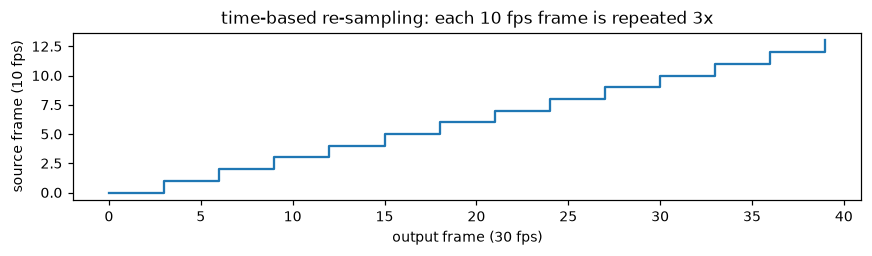

In [3]:
src_fps, out_fps = meta["src_fps"], meta["fps"]
k = np.arange(40)                                   # first 40 output frames
src_index = np.floor(k / out_fps * src_fps + 1e-9).astype(int)
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.step(k, src_index, where="post"); ax.set_xlabel("output frame (30 fps)"); ax.set_ylabel("source frame (10 fps)")
ax.set_title("time-based re-sampling: each 10 fps frame is repeated 3x"); plt.tight_layout(); plt.show()

## A3. From frames to a clip

For a key frame $k$, the clip is
$$\{\,k + (j - 16)\cdot s \;:\; j = 0..31\,\}, \qquad s = \texttt{FRAME\_RATE} = 2$$
Indices outside the video are clamped to the first or last frame. This is `ParkClipDataset.clip_indices`.
Below: which frames make up the clip around key frame 600 (second 20), and 8 of the 32 frames.

clip indices: [568, 570, 572, 574, 576, 578, 580, 582, 584, 586, 588, 590, 592, 594, 596, 598, 600, 602, 604, 606, 608, 610, 612, 614, 616, 618, 620, 622, 624, 626, 628, 630]
span = 2.07 s, key frame sits at position 16 of the clip


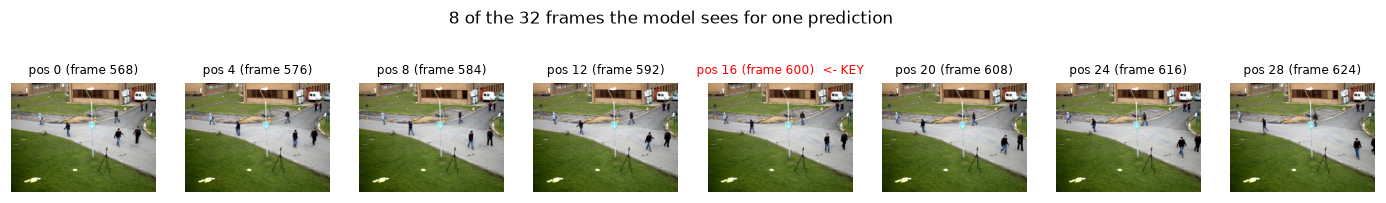

In [4]:
FR = ROOT / "data/frames/vtest"
frames = sorted(FR.glob("*.jpg"))
T, STRIDE, KEY = 32, 2, 600
idx = np.clip(KEY + (np.arange(T) - T // 2) * STRIDE, 0, len(frames) - 1)
print("clip indices:", idx.tolist())
print(f"span = {(idx[-1] - idx[0]) / 30:.2f} s, key frame sits at position {T // 2} of the clip")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
for ax, j in zip(axes, range(0, 32, 4)):
    ax.imshow(Image.open(frames[idx[j]])); ax.axis("off")
    ax.set_title(f"pos {j} (frame {idx[j]})" + ("  <- KEY" if j == 16 else ""), fontsize=8,
                 color="red" if j == 16 else "black")
plt.suptitle("8 of the 32 frames the model sees for one prediction", y=1.02); plt.show()

## A4. Box formats: a common source of bugs

Three coordinate systems appear in this pipeline:

| where | format | example |
|---|---|---|
| annotation CSV / JSON | normalised corners $(x_1,y_1,x_2,y_2)\in[0,1]$ | `[0.40, 0.33, 0.46, 0.58]` |
| dataset, after resize | pixel corners | `[182, 84, 209, 148]` |
| model output and loss | **normalised centre-size** $(c_x,c_y,w,h)$ | `[0.43, 0.46, 0.06, 0.25]` |

DETR-style models regress $(c_x,c_y,w,h)$ through a sigmoid, so all four numbers live in $[0,1]$.

In [5]:
from models.transformer.util import box_ops         # upstream helpers

W_, H_ = 455, 256                                    # a 16:9 frame resized to short side 256
norm_xyxy = torch.tensor([[0.40, 0.33, 0.46, 0.58]])
pix_xyxy  = norm_xyxy * torch.tensor([W_, H_, W_, H_])
norm_cxcywh = box_ops.box_xyxy_to_cxcywh(norm_xyxy)
print("normalised xyxy  :", norm_xyxy.numpy().round(3))
print("pixel xyxy       :", pix_xyxy.numpy().round(1))
print("normalised cxcywh:", norm_cxcywh.numpy().round(3))
print("round trip ok    :", torch.allclose(box_ops.box_cxcywh_to_xyxy(norm_cxcywh), norm_xyxy))

normalised xyxy  : [[0.4  0.33 0.46 0.58]]
pixel xyxy       : [[182.   84.5 209.3 148.5]]
normalised cxcywh: [[0.43  0.455 0.06  0.25 ]]
round trip ok    : True


---
# Part B: the architecture, layer by layer

```
clip [3,32,H,W] ─► CSN-152 backbone ─► features [2048, 4, H/16, W/16]
                         │                 └─► temporal pooling ('decode') ─► [2048, 1, H/16, W/16]
                         │                           └─► 1x1 conv to 256 ─► Transformer ENCODER (6 layers)
                         │                                                    └─► memory
                         │       15 learned QUERIES ─► Transformer DECODER (6 layers, attends to memory) ─► hs [6, B, 15, 256]
                         │                                                          ├─► box MLP ──► (cx,cy,w,h)
                         │                                                          ├─► action switch ─► P(person)
                         └─► features (all time steps) ─► context-aware head (queries cross-attend) ─► action logits
```

## B1. Build the real model
We load the released AVA 2.2 model (80 AVA actions) through our `build()`, exactly as `infer_video.py` does.

In [6]:
cfg = load_cfg("configs/ava_zero_shot.yaml")
logs = []
with quiet():
    model, criterion, _ = build(cfg, log=logs.append)
model.to(device).eval()
print("\n".join(logs))
AVA_NAMES = read_label_names(cfg.CONFIG.DATA.LABEL_PATH)   # {id: name}; output index = id - 1

reading C:\Users\itayb\Desktop\Technion\Year A\Semester B\CVProject\weights\TubeR_CSN152_AVA22.pth
  MODEL.TEMPORAL_DS_STRATEGY: avg -> decode (from checkpoint)
loaded 1170/1170 tensors from C:\Users\itayb\Desktop\Technion\Year A\Semester B\CVProject\weights\TubeR_CSN152_AVA22.pth (0 left at init, 0 checkpoint tensors unused, 0 shape mismatches)
backbone frozen up to 'layer3'
parameters: 91.8M total, 70.8M trainable


Note the line **`MODEL.TEMPORAL_DS_STRATEGY: avg -> decode (from checkpoint)`**. The yaml said `avg`, but
the weights were trained with `decode`. We come back to this in B4, because it's the most instructive bug
in this project.

Where do the ~92 M parameters live?

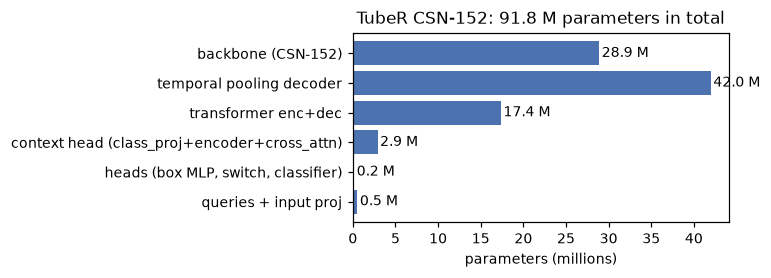

In [7]:
groups = {"backbone (CSN-152)": "backbone.body.", "temporal pooling decoder": "backbone.pool",
          "transformer enc+dec": "transformer.", "context head (class_proj+encoder+cross_attn)": ("class_proj", "encoder.", "cross_attn"),
          "heads (box MLP, switch, classifier)": ("bbox_embed", "class_embed_b", "class_fc"),
          "queries + input proj": ("query_embed", "input_proj")}
counts = {}
for gname, pref in groups.items():
    pref = pref if isinstance(pref, tuple) else (pref,)
    counts[gname] = sum(p.numel() for n, p in model.named_parameters() if n.startswith(pref)) / 1e6
total = sum(p.numel() for p in model.parameters()) / 1e6
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(list(counts), list(counts.values()), color="#4C72B0"); ax.invert_yaxis()
for i, v in enumerate(counts.values()): ax.text(v + 0.3, i, f"{v:.1f} M", va="center")
ax.set_xlabel("parameters (millions)"); ax.set_title(f"TubeR CSN-152: {total:.1f} M parameters in total")
plt.tight_layout(); plt.show()

## B2. The backbone: a *Channel-Separated* 3D CNN (CSN)

A normal 3D convolution with $C$ input channels, $C$ output channels and a $3\times3\times3$ kernel has
$27C^2$ weights. CSN factorises it into
1. a **$1\times1\times1$ conv** that mixes channels ($C^2$ weights), and
2. a **depth-wise $3\times3\times3$ conv**, one filter per channel ($27C$ weights) that mixes space and time.

That's roughly 27× cheaper, which is what lets a 152-layer 3D network fit. Below is one real bottleneck block
from the model: see `groups=` on `conv3`.

In [8]:
blk = model.backbone.body.layer3[0]
print(blk)
C = 256
full  = 27 * C * C
sep   = C * C + 27 * C
print(f"\nfull 3x3x3 conv, C={C}: {full:,} weights | channel-separated: {sep:,} weights  ->  {full/sep:.1f}x fewer")

ResNeXtBottleneck(
  (conv1): Conv3d(512, 256, kernel_size=(1, 1, 1), stride=(1, 1, 1), bias=False)
  (bn1): BatchNorm3d(256, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv3d(256, 256, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1), groups=256, bias=False)
  (bn3): BatchNorm3d(256, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv3d(256, 1024, kernel_size=(1, 1, 1), stride=(1, 1, 1), bias=False)
  (bn4): BatchNorm3d(1024, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (down_sample): Sequential(
    (0): Conv3d(512, 1024, kernel_size=(1, 1, 1), stride=(2, 2, 2), bias=False)
    (1): BatchNorm3d(1024, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
)

full 3x3x3 conv, C=256: 1,769,472 weights | channel-separated: 72,448 weights  ->  24.4x fewer


## B3. A real forward pass, with every intermediate shape

We load the clip around key frame 600 exactly as training does (resize so the short side is 256, ImageNet
normalisation), then use **forward hooks** to record the shape of every stage.

In [9]:
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def load_clip(frame_dir, key, T=32, stride=2, short=256):
    files = sorted(Path(frame_dir).glob("*.jpg"))
    ids = np.clip(key + (np.arange(T) - T // 2) * stride, 0, len(files) - 1)
    w0, h0 = Image.open(files[0]).size
    s = short / min(w0, h0); size = (round(w0 * s), round(h0 * s))
    imgs = [np.asarray(Image.open(files[i]).convert("RGB").resize(size, Image.BILINEAR)) for i in ids]
    x = (np.stack(imgs).astype(np.float32) / 255 - MEAN) / STD           # T,H,W,3
    return torch.from_numpy(x).permute(3, 0, 1, 2).float(), imgs[T // 2]  # [3,T,H,W], key-frame image

clip, key_img = load_clip(FR, 600)
shapes = {}
def rec(name):
    def hook(mod, inp, out):
        o = out[0] if isinstance(out, (tuple, list)) else out
        shapes[name] = tuple(o.tensors.shape) if hasattr(o, "tensors") else tuple(o.shape)
    return hook
hooks = [model.backbone.body.register_forward_hook(rec("1 backbone body (CSN-152)")),
         model.input_proj.register_forward_hook(rec("2 input_proj 2048->256 (after temporal pooling)")),
         model.transformer.register_forward_hook(rec("3 transformer decoder output hs")),
         model.bbox_embed.register_forward_hook(rec("4 box MLP (per decoder layer)")),
         model.class_embed_b.register_forward_hook(rec("5 action switch logits")),
         model.class_proj.register_forward_hook(rec("6 class_proj (context head, all time steps)")),
         model.class_fc.register_forward_hook(rec("7 action classifier logits"))]
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
    out = model([clip.to(device)])
for h in hooks: h.remove()
print(f"input clip: {tuple(clip.shape)}   (channels, time, height, width)\n")
for k_, v in sorted(shapes.items()): print(f"{k_:52s} {v}")
print("\nfinal outputs:", {k_: tuple(v.shape) for k_, v in out.items() if torch.is_tensor(v)})

input clip: (3, 32, 256, 341)   (channels, time, height, width)

1 backbone body (CSN-152)                            (1, 2048, 4, 16, 22)
2 input_proj 2048->256 (after temporal pooling)      (1, 256, 1, 16, 22)
3 transformer decoder output hs                      (6, 1, 15, 256)
4 box MLP (per decoder layer)                        (6, 1, 15, 4)
5 action switch logits                               (6, 1, 15, 3)
6 class_proj (context head, all time steps)          (1, 256, 4, 16, 22)
7 action classifier logits                           (6, 1, 15, 80)

final outputs: {'pred_logits': (1, 15, 80), 'pred_boxes': (1, 15, 4), 'pred_logits_b': (1, 15, 3)}


Reading the shapes:
- The backbone reduces **time by 8** (32 → 4) and **space by 16** (256×341 → 16×22), while channels grow to 2048.
- Temporal pooling squeezes the 4 time steps into **1**, because the boxes are predicted for the key frame only.
  The 1×1 conv then maps 2048 → 256, the transformer's width.
- `hs` is `[6, 1, 15, 256]`: **6 decoder layers × 15 queries × 256-d**. Every decoder layer gets its own
  predictions (the "auxiliary losses"); the last one is the answer.
- The **context head** (`class_proj`) works on the *un-pooled* features `[256, 4, 16, 22]`, so the action
  classifier still sees motion over time.

## B4. Temporal pooling, and the bug we found

In AVA mode the model predicts for the key frame, so the 4 temporal feature slices must be merged into 1.
Upstream supports:
- `avg`: average the 4 slices. No parameters.
- `decode`: a small transformer decoder with **one learned query** that attends over the time axis at every
  spatial position, so it *learns* which moments matter. It has parameters (`backbone.query_pool`, `backbone.pool_decoder`).

The released AVA 2.2 checkpoint was trained with `decode`, but the config shipped with the code says `avg`.
PyTorch's usual way of loading pretrained weights skips unknown keys, so an `avg` model loads "successfully"
and the pooling decoder's weights are silently thrown away. The transformer then gets features it has never
seen. Let's reproduce that:

In [10]:
from models.tuber_ava import build_model as upstream_build_model
from parktuber.checkpoint import load_pretrained, torch_load

cfg_avg = load_cfg("configs/ava_zero_shot.yaml")
cfg_avg.CONFIG.MODEL.TEMPORAL_DS_STRATEGY = "avg"          # what the published yaml says
with quiet():
    model_avg, _, _ = upstream_build_model(cfg_avg)
rep = load_pretrained(model_avg, torch_load(cfg_avg.CONFIG.FINETUNE.INIT_FROM), cfg_avg, log=lambda *_: None)
print("tensors in checkpoint that the 'avg' model has no place for:")
for k_ in rep["unused"][:6]: print("   ", k_)
print(f"   ... {len(rep['unused'])} in total")
model_avg.to(device).eval();

tensors in checkpoint that the 'avg' model has no place for:
    backbone.query_pool.weight
    backbone.pool_decoder.layers.0.self_attn.in_proj_weight
    backbone.pool_decoder.layers.0.self_attn.in_proj_bias
    backbone.pool_decoder.layers.0.self_attn.out_proj.weight
    backbone.pool_decoder.layers.0.self_attn.out_proj.bias
    backbone.pool_decoder.layers.0.multihead_attn.in_proj_weight
   ... 21 in total


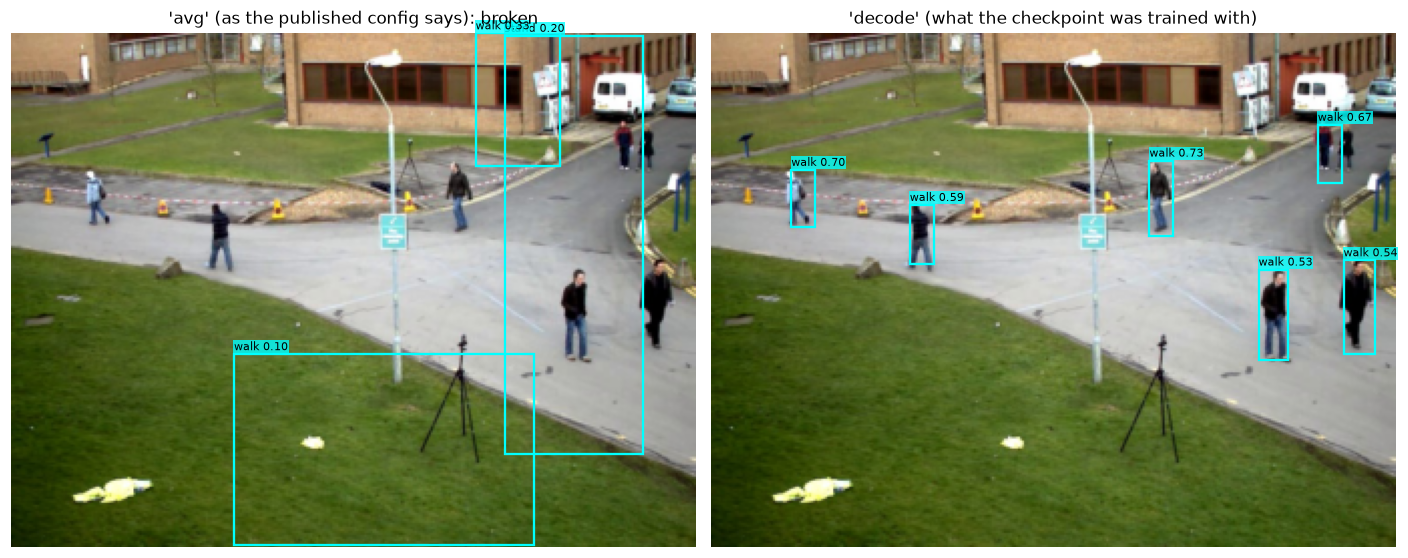

In [11]:
def detect(m, clip, thresh=0.5):
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
        o = m([clip.to(device)])
    H, W = clip.shape[-2:]
    scores, boxes, person = postprocess(o, torch.tensor([[H, W]]), 0.0)
    return o, scores[0], boxes[0], person[0]

def draw_dets(ax, img, boxes, person, scores=None, names=None, thresh=0.5, title=""):
    ax.imshow(img); ax.axis("off"); ax.set_title(title)
    for q in np.where(person > thresh)[0]:
        x1, y1, x2, y2 = boxes[q]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, color="cyan"))
        lab = f"{person[q]:.2f}"
        if scores is not None and names is not None:
            a = int(np.argmax(scores[q])); lab = f"{names.get(a + 1, a)} {scores[q][a]:.2f}"
        ax.text(x1, y1 - 2, lab, color="black", fontsize=7, bbox=dict(fc="cyan", alpha=0.8, pad=0.5, lw=0))

_, s_avg, b_avg, p_avg = detect(model_avg, clip)
out, s_dec, b_dec, p_dec = detect(model, clip)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_dets(axes[0], key_img, b_avg, p_avg, s_avg, AVA_NAMES, title="'avg' (as the published config says): broken")
draw_dets(axes[1], key_img, b_dec, p_dec, s_dec, AVA_NAMES, title="'decode' (what the checkpoint was trained with)")
plt.tight_layout(); plt.show()
del model_avg; torch.cuda.empty_cache()

Same weights, same clip, one config value different. **Lesson for any pretrained model:** check that every
checkpoint tensor was actually used, not only that the load didn't crash. Our loader now prints
`N checkpoint tensors unused`, and it reads structural settings from the config stored inside the checkpoint
(`parktuber/checkpoint.py: sync_architecture`).

## B5. Tubelet queries: set prediction instead of anchors

The decoder starts from **15 learned query vectors** (`model.query_embed.weight`, shape `[15, 256]`). Each
query can be thought of as a "slot" that grabs one person. For every query, the model outputs:
- a box, and
- the **action switch**, a 3-way softmax (index 1 = *person*, index 2 = *no object*; index 0 is unused in AVA mode),
- action logits.

There's no NMS and there are no anchors. Training (Part C) teaches the queries to *not* duplicate each other.
Here are all 15 queries for our clip:

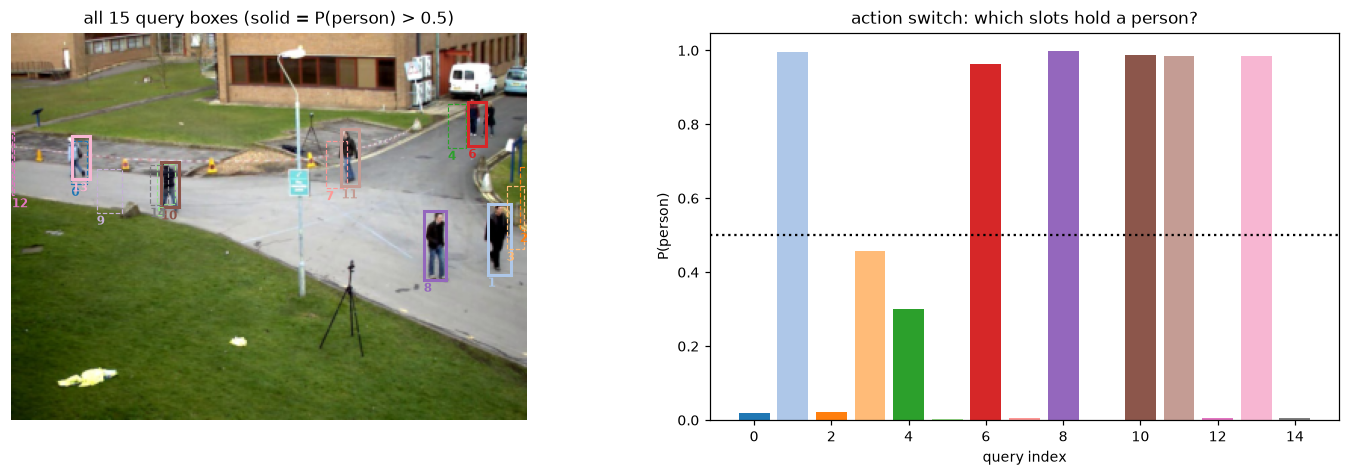

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].imshow(key_img); axes[0].axis("off"); axes[0].set_title("all 15 query boxes (solid = P(person) > 0.5)")
cmap = plt.get_cmap("tab20")
for q in range(15):
    x1, y1, x2, y2 = b_dec[q]; on = p_dec[q] > 0.5
    axes[0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2 if on else 0.8,
                                        ls="-" if on else "--", color=cmap(q)))
    axes[0].text(x1, y2 + 8, str(q), color=cmap(q), fontsize=8, weight="bold")
axes[1].bar(range(15), p_dec, color=[cmap(q) for q in range(15)])
axes[1].axhline(0.5, color="k", ls=":"); axes[1].set_xlabel("query index"); axes[1].set_ylabel("P(person)")
axes[1].set_title("action switch: which slots hold a person?"); plt.tight_layout(); plt.show()

## B6. What does a query look at? Decoder cross-attention

In the last decoder layer, each query **cross-attends** to all $16\times22$ positions of the encoder memory.
Upstream returns these attention weights (averaged over the 8 heads) as the 4th output of the transformer.
We capture them with a hook and draw them for the confident people. Each query "lights up" around *its*
person, which is how a slot binds to an object without anchors.

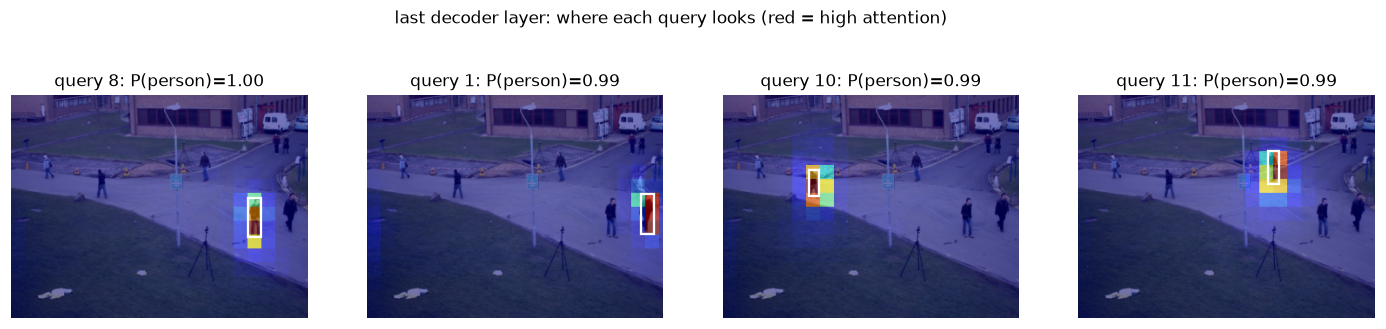

In [13]:
att = {}
h = model.transformer.register_forward_hook(lambda m, i, o: att.__setitem__("dec", o[3].float().cpu()))
o_, s_, b_, p_ = detect(model, clip); h.remove()
A = att["dec"][0]                                           # [15 queries, HW]
Hf, Wf = shapes["2 input_proj 2048->256 (after temporal pooling)"][-2:]
top = np.argsort(-p_)[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, q in zip(axes, top):
    amap = A[q].reshape(Hf, Wf).numpy()
    ax.imshow(key_img); ax.imshow(np.kron(amap, np.ones((16, 16)))[:key_img.shape[0], :key_img.shape[1]],
                                  alpha=0.55, cmap="jet"); ax.axis("off")
    x1, y1, x2, y2 = b_[q]
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, color="white"))
    ax.set_title(f"query {q}: P(person)={p_[q]:.2f}")
plt.suptitle("last decoder layer: where each query looks (red = high attention)", y=1.02); plt.show()

## B7. The *context-aware* classification head

Classifying the action from the box region alone ignores context: the bench someone sits on, the ball, the
other person in a fight. TubeR's head lets each query **cross-attend over the whole space-time feature volume**
(`class_proj` → 1-layer encoder → `cross_attn`). This attention runs over $T'\times H'\times W' = 4\times16\times22$
positions, so the head can also weigh the moments in time that matter.

Below: for one person, the head's attention summed over time (left), and how it is spread across the 4 time
slices (right).

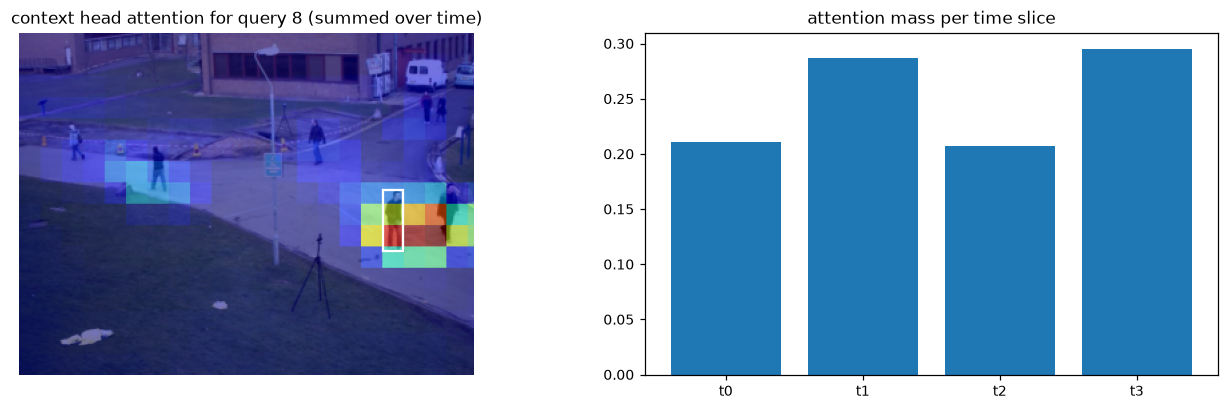

share of attention inside the person's own box: 9% -> the rest is context


In [14]:
att2 = {}
h = model.cross_attn.register_forward_hook(lambda m, i, o: att2.__setitem__("cls", o[1].float().cpu()))
_ = detect(model, clip); h.remove()
Tc = shapes["6 class_proj (context head, all time steps)"][2]
A2 = att2["cls"][-1]                                        # last decoder layer: [15 queries, T'*H'*W']
q = top[0]
vol = A2[q].reshape(Tc, Hf, Wf).numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].imshow(key_img)
axes[0].imshow(np.kron(vol.sum(0), np.ones((16, 16)))[:key_img.shape[0], :key_img.shape[1]], alpha=0.55, cmap="jet")
x1, y1, x2, y2 = b_[q]; axes[0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.5, color="white"))
axes[0].axis("off"); axes[0].set_title(f"context head attention for query {q} (summed over time)")
axes[1].bar([f"t{i}" for i in range(Tc)], vol.reshape(Tc, -1).sum(1)); axes[1].set_title("attention mass per time slice")
plt.tight_layout(); plt.show()
inside = vol.sum(0)[max(0, int(y1 // 16)):int(y2 // 16) + 1, max(0, int(x1 // 16)):int(x2 // 16) + 1].sum()
print(f"share of attention inside the person's own box: {inside / vol.sum():.0%} -> the rest is context")

## B8. From logits to scores: the action switch × multi-label sigmoid

For query $q$ and action $a$:
$$\text{score}_{q,a} = \underbrace{\operatorname{softmax}(z^{b}_q)_{\text{person}}}_{\text{action switch}} \times \underbrace{\sigma(z_{q,a})}_{\text{independent per action}}$$

Upstream also multiplies by a **hard gate** $[P(\text{person}) > 0.8]$. For evaluation we set that gate to 0
(`FINETUNE.EVAL_BINARY_THRESH`): average precision is computed by *ranking* detections, and a hard cut simply
deletes low-confidence ones. That's harmless for the fully trained AVA model, but it can wipe out everything
early in fine-tuning (upstream issue #27).

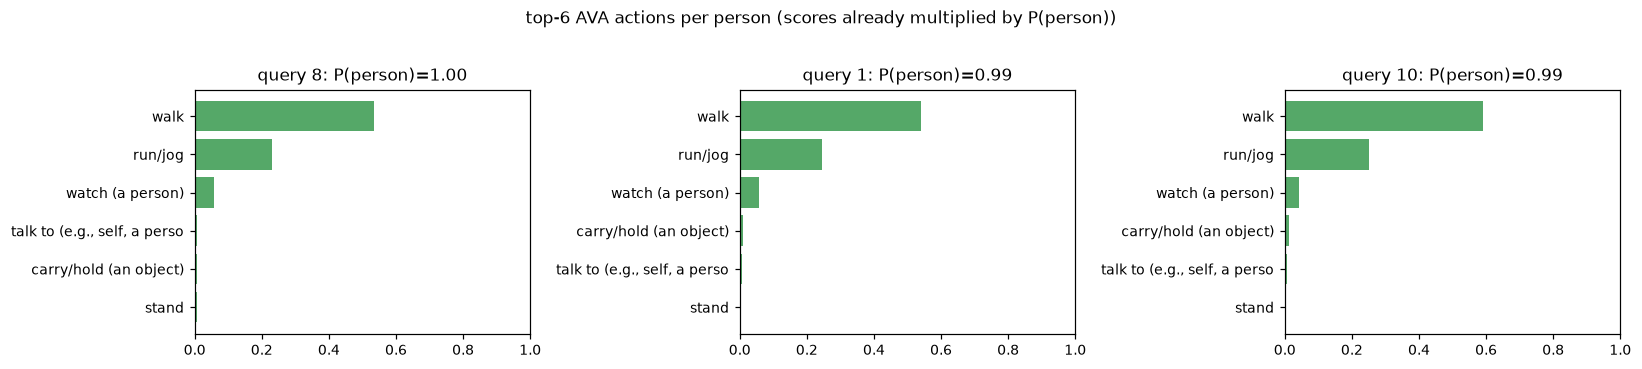

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, q in zip(axes, top[:3]):
    order = np.argsort(-s_[q])[:6]
    ax.barh([AVA_NAMES.get(a + 1, str(a))[:28] for a in order][::-1], s_[q][order][::-1], color="#55A868")
    ax.set_xlim(0, 1); ax.set_title(f"query {q}: P(person)={p_[q]:.2f}")
plt.suptitle("top-6 AVA actions per person (scores already multiplied by P(person))", y=1.03)
plt.tight_layout(); plt.show()

## B9. Do queries specialise? (the classic DETR figure)

Run the model over the whole video (one clip per second) and plot the **centre of every confident box, coloured
by which query produced it**. In DETR, each query tends to own a region and a box size, a learned,
data-driven replacement for anchors.

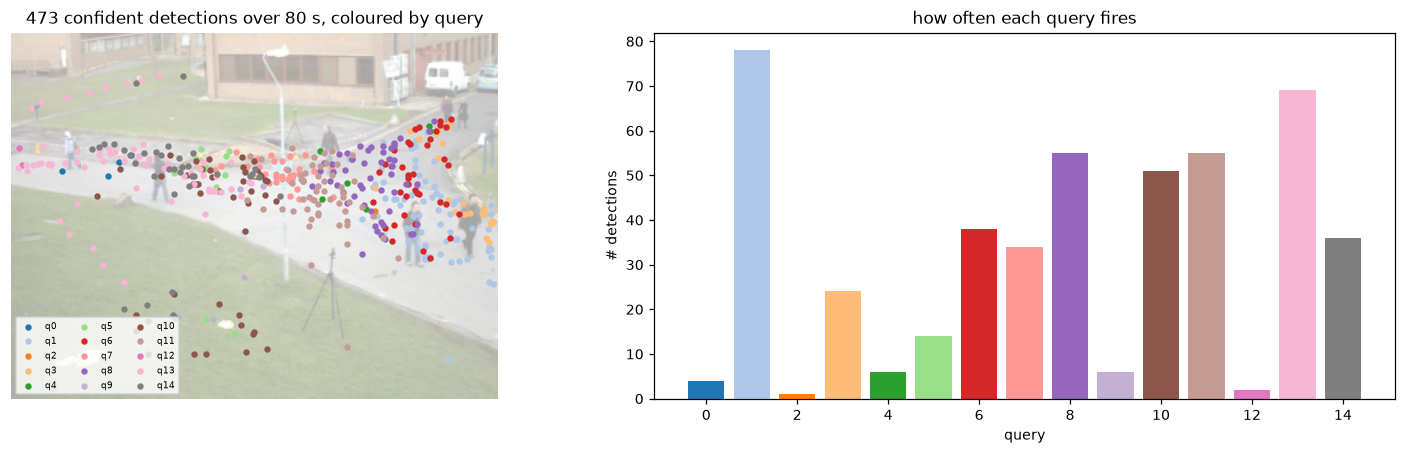

In [16]:
pts = []
for key in range(30, len(frames) - 30, 30):
    c_, _ = load_clip(FR, key)
    _, _, bb, pp = detect(model, c_)
    for q in np.where(pp > 0.5)[0]:
        x1, y1, x2, y2 = bb[q]; pts.append((q, (x1 + x2) / 2, (y1 + y2) / 2, y2 - y1))
pts = np.array(pts)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].imshow(key_img, alpha=0.35)
for q in range(15):
    m_ = pts[:, 0] == q
    if m_.any(): axes[0].scatter(pts[m_, 1], pts[m_, 2], s=10, color=cmap(q), label=f"q{q}")
axes[0].legend(fontsize=6, ncol=3, loc="lower left"); axes[0].axis("off")
axes[0].set_title(f"{len(pts)} confident detections over {len(frames) / 30:.0f} s, coloured by query")
use = np.bincount(pts[:, 0].astype(int), minlength=15)
axes[1].bar(range(15), use, color=[cmap(q) for q in range(15)]); axes[1].set_xlabel("query"); axes[1].set_ylabel("# detections")
axes[1].set_title("how often each query fires"); plt.tight_layout(); plt.show()

Some queries fire constantly and others almost never; many are "spare slots". This is also why
`QUERY_NUM` (15) is a hard upper limit on people per clip: for crowded park scenes, raise it (the extra
queries start untrained, see `docs/04`).

---
# Part C: how TubeR learns

## C1. Hungarian matching: why set prediction needs it

The model outputs 15 (box, class) guesses in **no particular order**; the ground truth has, say, 3 people. Which
query should be pushed towards which person? DETR's answer: find the **one-to-one assignment with minimum total
cost** (the Hungarian algorithm, `scipy.optimize.linear_sum_assignment`). Matched queries learn their person;
all others learn "no object". That's what removes the need for NMS: two queries can't both claim the same person.

A toy example with 5 predictions and 3 ground-truth boxes:

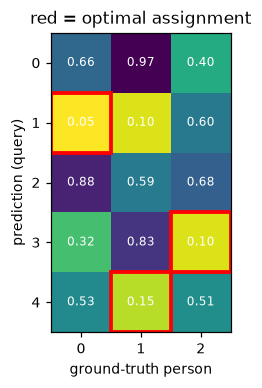

matches (query -> gt): {1: 0, 3: 2, 4: 1} | total cost 0.3
note: query 1 has the lowest cost for BOTH gt 0 and gt 1, but a one-to-one matching lets it claim only one


In [17]:
from scipy.optimize import linear_sum_assignment
rng = np.random.default_rng(1)
cost = rng.uniform(0.3, 1.0, (5, 3)); cost[1, 0] = 0.05; cost[3, 2] = 0.1; cost[4, 1] = 0.15; cost[1, 1] = 0.1
rows, cols = linear_sum_assignment(cost)
fig, ax = plt.subplots(figsize=(4.5, 3.6))
ax.imshow(cost, cmap="viridis_r")
for i in range(5):
    for j in range(3): ax.text(j, i, f"{cost[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
for i, j in zip(rows, cols): ax.add_patch(patches.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="red", lw=2.5))
ax.set_xlabel("ground-truth person"); ax.set_ylabel("prediction (query)"); ax.set_title("red = optimal assignment")
plt.tight_layout(); plt.show()
print("matches (query -> gt):", dict(zip(rows.tolist(), cols.tolist())), "| total cost", cost[rows, cols].sum().round(2))
print("note: query 1 has the lowest cost for BOTH gt 0 and gt 1, but a one-to-one matching lets it claim only one")

## C2. The real matcher on the real model

TubeR's matching cost (`models/detr/matcher.py`) for query $i$ and ground truth $j$ is
$$C_{ij} = 5\,\lVert b_i - \hat b_j\rVert_1 \;-\; 2\,\mathrm{GIoU}(b_i,\hat b_j) \;-\; 12\,P_i(\text{person})$$
Let's pretend the confident detections on our clip are the ground truth and run the upstream matcher.

ground truth was built from queries: [8, 1, 10]
matcher assigned queries          : [1, 8, 10] -> gt [1, 0, 2]


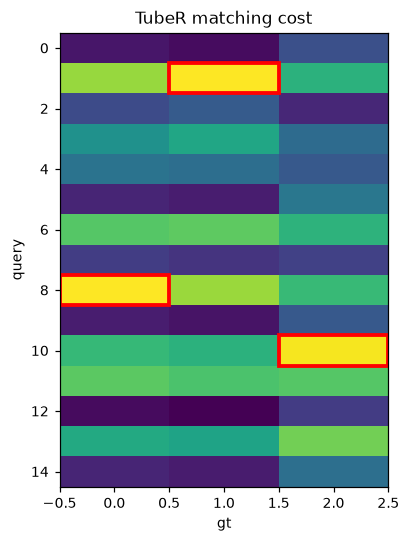

In [18]:
from models.detr.matcher import HungarianMatcher
o32 = {k_: v.float() for k_, v in o_.items() if torch.is_tensor(v)}
Hc, Wc = clip.shape[-2:]
gt_q = [q for q in top if p_[q] > 0.5][:3]
gt_xyxy = torch.tensor(b_[gt_q] / np.array([Wc, Hc, Wc, Hc]), dtype=torch.float32)
gt_xyxy[:, :2] += 0.01                                        # jitter a little, like an imperfect annotator
gt_cxcywh = box_ops.box_xyxy_to_cxcywh(gt_xyxy)
targets = [{"boxes": torch.cat([torch.full((len(gt_q), 1), 16.), gt_cxcywh], 1).to(device),
            "labels": torch.zeros(len(gt_q), 80, device=device)}]
matcher = HungarianMatcher(cost_class=12, cost_bbox=5, cost_giou=2)
(src, tgt), = matcher(o32, targets)
print("ground truth was built from queries:", [int(q) for q in gt_q])
print("matcher assigned queries          :", src.tolist(), "-> gt", tgt.tolist())

ob = o32["pred_boxes"][0]
c_l1 = torch.cdist(ob, gt_cxcywh.to(device), p=1)
c_giou = -box_ops.generalized_box_iou(box_ops.box_cxcywh_to_xyxy(ob), box_ops.box_cxcywh_to_xyxy(gt_cxcywh.to(device)))
c_cls = -o32["pred_logits_b"][0].softmax(-1)[:, 1:2].repeat(1, len(gt_q))
Cm = (5 * c_l1 + 2 * c_giou + 12 * c_cls).cpu().numpy()
fig, ax = plt.subplots(figsize=(3.8, 5)); ax.imshow(Cm, cmap="viridis_r", aspect="auto")
for i, j in zip(src.tolist(), tgt.tolist()): ax.add_patch(patches.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="red", lw=2.5))
ax.set_xlabel("gt"); ax.set_ylabel("query"); ax.set_title("TubeR matching cost"); plt.tight_layout(); plt.show()

## C3. The losses

After matching, `SetCriterionAVA` computes, **for every one of the 6 decoder layers**:

| loss | on which queries | what | weight |
|---|---|---|---|
| `loss_ce_b` | all 15 | cross-entropy of the action switch (person vs. no object; no-object down-weighted ×0.1 because most slots are empty) | 1 |
| `loss_ce` | all (matched ×10) | multi-label BCE over the actions | 12 |
| `loss_bbox` | matched | L1 on $(c_x,c_y,w,h)$ | 5 |
| `loss_giou` | matched | $1-\mathrm{GIoU}$, scale-invariant box overlap | 2 |

Let's compute them on our pseudo-labelled clip, giving everyone the AVA label "walk" (id 14):

last decoder layer:

 {'loss_ce': 0.028, 'loss_ce_b': 0.307, 'loss_bbox': 0.03, 'loss_giou': 0.296}
weighted total over all 6 layers: 9.09


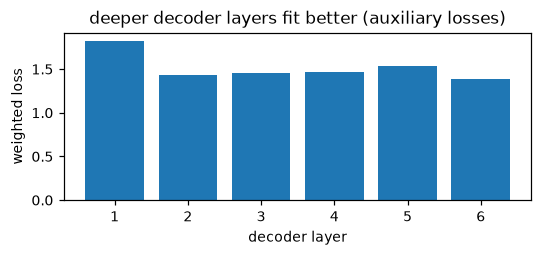

In [19]:
targets[0]["labels"][:, 14 - 1] = 1.0
criterion.to(device)
ld = criterion(o32 | {"aux_outputs": [{k_: v.float() for k_, v in a.items()} for a in o_["aux_outputs"]]}, targets)
wd = criterion.weight_dict
last = {k_: float(v) for k_, v in ld.items() if k_ in ("loss_ce", "loss_ce_b", "loss_bbox", "loss_giou")}
print("last decoder layer:", {k_: round(v, 3) for k_, v in last.items()})
total = sum(ld[k_] * wd[k_] for k_ in ld if k_ in wd)
per_layer = [sum(float(ld[f"{n}_{i}"]) * wd[n] for n in last) for i in range(5)] + [sum(v * wd[k_] for k_, v in last.items())]
print(f"weighted total over all 6 layers: {float(total):.2f}")
plt.figure(figsize=(5, 2.4)); plt.bar(range(1, 7), per_layer); plt.xlabel("decoder layer"); plt.ylabel("weighted loss")
plt.title("deeper decoder layers fit better (auxiliary losses)"); plt.tight_layout(); plt.show()

**Training tricks this project adds for small GPUs and small data** (`parktuber/engine.py`, `model.py`):
- **bf16 autocast** for the network, with the **loss in fp32**: PyTorch refuses BCE under autocast, and fp32 is safer anyway.
- **Gradient accumulation**: batch 1 × 8 steps behaves like batch 8 for the optimizer.
- **Frozen BatchNorm**: BN statistics estimated from 1 clip are noise, so we keep the AVA statistics (`FREEZE_BN`).
- **Partial freezing** of the backbone (`FREEZE_BACKBONE: layer3`): fewer parameters to fit from little data, and much less memory.

---
# Part D: how it's scored

## D1. IoU and Average Precision

A detection of action $a$ is a **true positive** if it overlaps an unmatched ground-truth box that has action
$a$ with **IoU ≥ 0.5**; otherwise it's a false positive. Sort all detections of class $a$ by score and sweep a
threshold, and you get a precision–recall curve. **AP** is the area under it. **frame-mAP** is the mean AP
over classes, computed on key frames. This is exactly the AVA metric; the upstream evaluator is a port of the
official one.

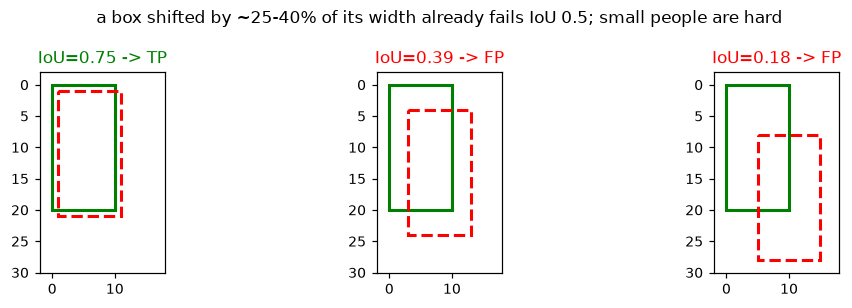

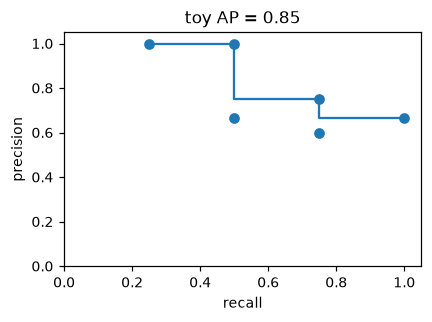

In [20]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter)

gt = [0, 0, 10, 20]
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, d in zip(axes, ([1, 1, 11, 21], [3, 4, 13, 24], [5, 8, 15, 28])):
    ax.add_patch(patches.Rectangle(gt[:2], 10, 20, fill=False, ec="g", lw=2))
    ax.add_patch(patches.Rectangle(d[:2], 10, 20, fill=False, ec="r", lw=2, ls="--"))
    v = iou(gt, d); ax.set_xlim(-2, 18); ax.set_ylim(30, -2); ax.set_aspect("equal")
    ax.set_title(f"IoU={v:.2f} -> {'TP' if v >= .5 else 'FP'}", color="g" if v >= .5 else "r")
plt.suptitle("a box shifted by ~25-40% of its width already fails IoU 0.5; small people are hard"); plt.tight_layout(); plt.show()

# toy AP: 6 detections for one class, 4 GT boxes in total
tp = np.array([1, 1, 0, 1, 0, 1]); n_gt = 4
prec = np.cumsum(tp) / np.arange(1, len(tp) + 1); rec = np.cumsum(tp) / n_gt
ap = sum((rec[i] - (rec[i-1] if i else 0)) * prec[i:].max() for i in range(len(tp)))   # VOC-style, interpolated
plt.figure(figsize=(4, 3)); plt.step(rec, [prec[i:].max() for i in range(len(tp))], where="post"); plt.scatter(rec, prec)
plt.xlabel("recall"); plt.ylabel("precision"); plt.xlim(0, 1.05); plt.ylim(0, 1.05); plt.title(f"toy AP = {ap:.2f}")
plt.tight_layout(); plt.show()

---
# Part E: fine-tuning in practice

## E1. Initialising the new head from AVA

Our park label set has 14 classes, and AVA has 80. The final layer `class_fc` is a $[C \times 256]$ matrix,
one row per class. Instead of starting the 14 new rows at random, `configs/ava_to_park.yaml` says which AVA
rows to copy (or average): `walk ← AVA 14`, `fight_push ← mean(AVA 64, 76, 66)`, and so on. So the fine-tuned
model *starts* with sensible predictions (zero-shot), and training only has to adapt them.

  class_fc[0] 'stand': from AVA ids [12]
  class_fc[1] 'walk': from AVA ids [14]
  class_fc[2] 'run': from AVA ids [10]
  class_fc[3] 'sit': from AVA ids [11]
  class_fc[4] 'lie_down': from AVA ids [8]
  class_fc[5] 'bend_crouch': from AVA ids [1, 3]
  class_fc[6] 'ride_bike_scooter': from AVA ids [49]
  class_fc[7] 'fall_down': from AVA ids [5]
  class_fc[8] 'fight_push': from AVA ids [64, 76, 66]
  class_fc[9] 'throw': from AVA ids [58]
  class_fc[10] 'carry_object': from AVA ids [17]
  class_fc[11] 'talk_to_person': from AVA ids [79]
  class_fc[12] 'use_phone': from AVA ids [57, 15]
  class_fc[13] 'hug': from AVA ids [70]


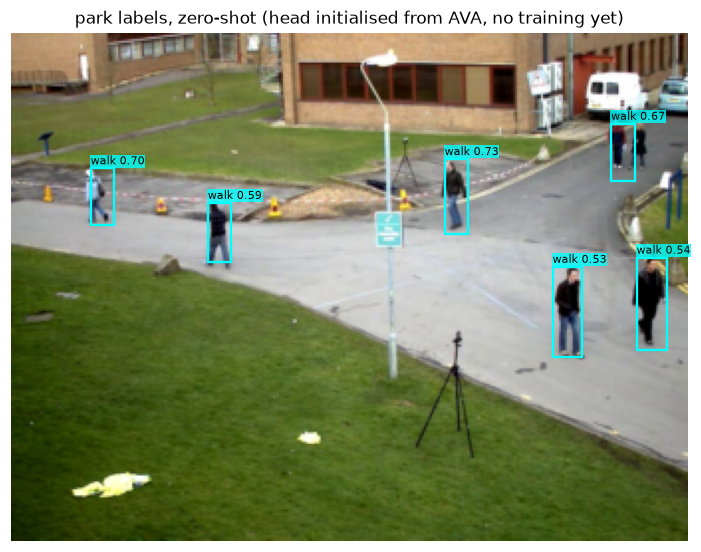

In [21]:
cfg_p = load_cfg("configs/park_csn152_8gb.yaml")
logs = []
with quiet():
    model_p, _, _ = build(cfg_p, log=logs.append)
print("\n".join(l for l in logs if "class_fc" in l))
model_p.to(device).eval()
PARK = read_label_names(cfg_p.CONFIG.DATA.LABEL_PATH)
_, sp, bp, pp = detect(model_p, clip)
fig, ax = plt.subplots(figsize=(8, 6))
draw_dets(ax, key_img, bp, pp, sp, PARK, title="park labels, zero-shot (head initialised from AVA, no training yet)")
plt.show()
del model_p; torch.cuda.empty_cache()

## E2. A real (tiny) fine-tuning run, on a task that *requires* motion

We don't have annotated park footage yet, so we build a small synthetic dataset with
[`notebooks/motion_toy.py`](motion_toy.py): identical grey figures on a lawn. Some stand still (`stand`), and some
move in a random direction (`run`). **Colour, size and position carry no information about the class; only
motion does.** An image model could never solve this. A video model can, if it really uses the time axis.

> **A lesson in shortcut learning.** The first version of this experiment reused the smoke-test videos, where
> the runner was always *blue* and always in the *bottom half*. The model scored well, but the frozen-clip test
> in E3 showed it had learned "blue, bottom → run" and ignored motion completely. When a model looks good, ask
> *which* signal it uses. In park footage the equivalents are "the jogging path is in the top-left → run" and
> "the benches are here → sit": splitting by camera (docs/03) and testing on unseen cameras is how you catch them.

The workflow is the same as for real data: videos → `extract_frames.py` → CSV → `build_annotations.py` → train.

8 video(s) -> C:\Users\itayb\Desktop\Technion\Year A\Semester B\CVProject\runs\motion_toy\frames @ 30.0 fps
[ok] train00_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] train01_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] train02_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] train03_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] train04_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] train05_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] val06_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0
[ok] val07_toy: 240 frames (8.0s) 320x240@25.00 -> 320x240@30.0 

train: 42 key-frames, 126 boxes, groups=['train']
val: 14 key-frames, 42 boxes, groups=['val']

class                              train     val
stand                                 56      21
run                                   70      21 



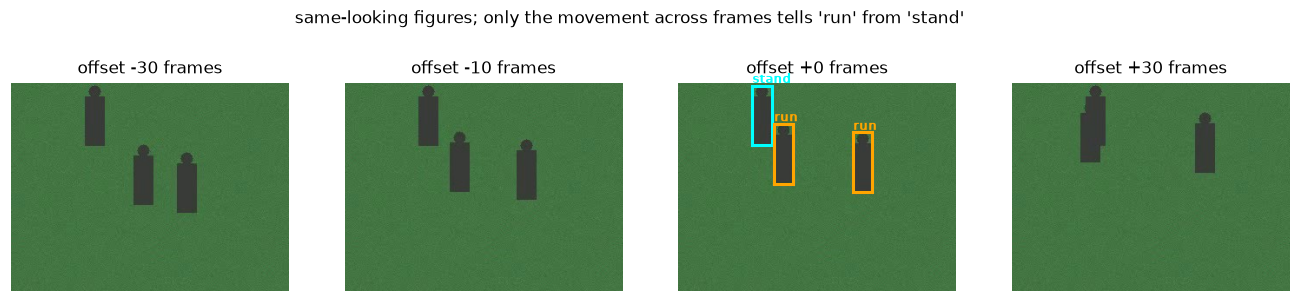

In [22]:
sys.path.insert(0, str(ROOT / "notebooks"))
import motion_toy as mt
TOY = ROOT / "runs/motion_toy"
mt.make_dataset(TOY, n_train=6, n_val=2, seed=0)
for cmd in (["tools/extract_frames.py", "--videos", str(TOY / "videos"), "--out", str(TOY / "frames"), "--short-side", "0", "--workers", "1", "--overwrite"],
            ["tools/build_annotations.py", "--csv", str(TOY / "annotations.csv"), "--frames", str(TOY / "frames"), "--labels", str(TOY / "labels.pbtxt"),
             "--out", str(TOY / "anno"), "--group-regex", r"^(train|val)", "--val-groups", "val"]):
    print(subprocess.run([sys.executable, *cmd], capture_output=True, text=True).stdout.strip(), "\n")

# what the model sees: 4 frames of one training clip, with the key-frame labels
anno = json.load(open(TOY / "anno/train.json"))
key = anno["frame_keys_list"][3]; vid, kf = key.rsplit(",", 1)
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, off in zip(axes, (-30, -10, 0, 30)):
    ax.imshow(Image.open(TOY / "frames" / vid / f"{int(kf) + off:06d}.jpg")); ax.axis("off"); ax.set_title(f"offset {off:+d} frames")
    if off == 0:
        for (x1, y1, x2, y2), acts in zip(anno["video_frame_bbox"][key]["bboxes"], anno["video_frame_bbox"][key]["acts"]):
            c_ = "orange" if acts == [1] else "cyan"
            ax.add_patch(patches.Rectangle((x1 * 320, y1 * 240), (x2 - x1) * 320, (y2 - y1) * 240, fill=False, ec=c_, lw=2))
            ax.text(x1 * 320, y1 * 240 - 3, "run" if acts == [1] else "stand", color=c_, fontsize=8, weight="bold")
plt.suptitle("same-looking figures; only the movement across frames tells 'run' from 'stand'", y=1.03); plt.show()

In [23]:
from parktuber.dataset import build_loader, ParkClipDataset
from parktuber.engine import build_scheduler, train_one_epoch, evaluate, autocast_ctx
from parktuber.model import param_groups

toy_yaml = "\n".join([
    "CONFIG:",
    "  DATA:",
    f"    FRAMES_DIR: \"{(TOY / 'frames').as_posix()}\"",
    f"    TRAIN_ANNO: \"{(TOY / 'anno/train.json').as_posix()}\"",
    f"    VAL_ANNO: \"{(TOY / 'anno/val.json').as_posix()}\"",
    f"    LABEL_PATH: \"{(TOY / 'labels.pbtxt').as_posix()}\"",
    "    NUM_WORKERS: 0",
    "  TRAIN:",
    "    EPOCH_NUM: 10",
    "    LR_MILESTONE: [8]",
    "  FINETUNE:",
    f"    HEAD_INIT_MAPPING: \"{(TOY / 'ava_to_toy.yaml').as_posix()}\"",
    "    GRAD_ACCUM: 4",
    "  LOG:",
    f"    BASE_PATH: \"{(TOY / 'runs').as_posix()}\"",
    "    EXP_NAME: \"notebook\""])
(TOY / "toy.yaml").write_text(toy_yaml)
cfg_t = load_cfg(str(TOY / "toy.yaml"))       # everything else comes from the defaults in parktuber/config.py
torch.manual_seed(0); np.random.seed(0)
with quiet():
    model_t, crit_t, _ = build(cfg_t, log=lambda *_: None)
    train_loader, val_loader = build_loader(cfg_t, "train"), build_loader(cfg_t, "val")
model_t.to(device); crit_t.to(device)
opt = torch.optim.AdamW(param_groups(model_t, cfg_t), lr=cfg_t.CONFIG.TRAIN.LR, weight_decay=cfg_t.CONFIG.TRAIN.W_DECAY)
sched = build_scheduler(opt, cfg_t, len(train_loader))
scaler = torch.amp.GradScaler("cuda", enabled=False)       # bf16 needs no loss scaling
print(f"train clips: {len(train_loader.dataset)}, val clips: {len(val_loader.dataset)}, "
      f"trainable params: {sum(p.numel() for p in model_t.parameters() if p.requires_grad) / 1e6:.1f} M")

[config] NUM_CLASSES 14 -> 2 (from C:\Users\itayb\Desktop\Technion\Year A\Semester B\CVProject\runs\motion_toy\labels.pbtxt)


train clips: 42, val clips: 14, trainable params: 70.8 M


Before training, let's record the **frozen-clip test** we'll use in E3, so there is a "before" to compare against.
For every validation figure we find the predicted box that overlaps it most, and read the share
$P(\text{run}) / (P(\text{run}) + P(\text{stand}))$ on (a) the real clip and (b) a *frozen* clip: the key frame
copied 32 times, with the same pixels in the key frame but no motion.

In [24]:
def motion_test(m, cfg_):
    ds = ParkClipDataset(cfg_, cfg_.CONFIG.DATA.VAL_ANNO, "val")
    res = {(c_, t_): [] for c_ in ("stand", "run") for t_ in ("real", "frozen")}
    m.eval()
    for i in range(len(ds)):
        clip_, tgt = ds[i]
        for tag, c_ in (("real", clip_), ("frozen", clip_[:, 16:17].repeat(1, 32, 1, 1))):
            with torch.no_grad(), autocast_ctx(cfg_):
                o = m([c_.to(device)])
            sc, bx, _ = postprocess(o, torch.tensor([list(c_.shape[-2:])]), 0.0)
            ious = box_ops.box_iou(tgt["raw_boxes"][:, 2:6], torch.from_numpy(bx[0]))[0].numpy()
            for g in range(len(ious)):
                q = ious[g].argmax()
                if ious[g, q] >= 0.3:
                    cls = "stand" if tgt["labels"][g, 0] > 0 else "run"
                    res[(cls, tag)].append(sc[0][q][1] / (sc[0][q][0] + sc[0][q][1] + 1e-6))
    return {k_: float(np.mean(v)) if v else float("nan") for k_, v in res.items()}

before = motion_test(model_t, cfg_t)
print({f"{c_}/{t_}": round(v, 3) for (c_, t_), v in before.items()})

{'stand/real': 0.008, 'stand/frozen': 0.003, 'run/real': nan, 'run/frozen': 0.008}


In [25]:
hist, t0 = [], time.time()
with quiet():
    r0 = evaluate(model_t, crit_t, val_loader, cfg_t, TOY / "eval/before", -1, log=lambda *_: None)
hist.append((0, float("nan"), r0["mAP"], r0["per_class_AP"]))
for ep in range(cfg_t.CONFIG.TRAIN.EPOCH_NUM):
    with quiet():
        st_ = train_one_epoch(model_t, crit_t, train_loader, opt, sched, scaler, cfg_t, ep, log=lambda *_: None)
        r = evaluate(model_t, crit_t, val_loader, cfg_t, TOY / f"eval/ep{ep}", ep, log=lambda *_: None)
    hist.append((ep + 1, st_["loss"], r["mAP"], r["per_class_AP"]))
    print(f"epoch {ep}: train loss {st_['loss']:7.2f} | val mAP {r['mAP']:.3f} | "
          + " ".join(f"{k_}={v:.3f}" for k_, v in r["per_class_AP"].items()) + f" | {time.time() - t0:.0f}s")

epoch 0: train loss  287.15 | val mAP 0.025 | stand=0.017 run=0.032 | 20s


epoch 1: train loss  136.67 | val mAP 0.165 | stand=0.005 run=0.326 | 38s


epoch 2: train loss   99.53 | val mAP 0.202 | stand=0.020 run=0.383 | 56s


epoch 3: train loss   84.14 | val mAP 0.140 | stand=0.060 run=0.219 | 73s


epoch 4: train loss   69.81 | val mAP 0.225 | stand=0.042 run=0.407 | 91s


epoch 5: train loss   58.46 | val mAP 0.415 | stand=0.179 run=0.652 | 108s


epoch 6: train loss   74.49 | val mAP 0.276 | stand=0.131 run=0.421 | 125s


epoch 7: train loss   56.83 | val mAP 0.297 | stand=0.179 run=0.414 | 142s


epoch 8: train loss   55.82 | val mAP 0.273 | stand=0.138 run=0.409 | 159s


epoch 9: train loss   53.98 | val mAP 0.338 | stand=0.148 run=0.528 | 176s


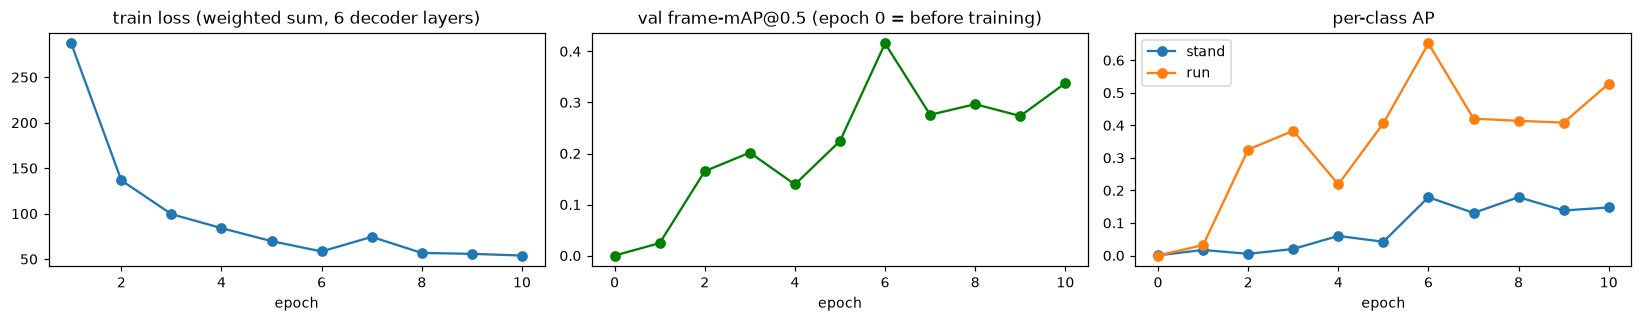

In [26]:
ep_, loss_, map_ = zip(*[(h[0], h[1], h[2]) for h in hist])
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].plot(ep_[1:], loss_[1:], "o-"); axes[0].set_title("train loss (weighted sum, 6 decoder layers)"); axes[0].set_xlabel("epoch")
axes[1].plot(ep_, map_, "o-", color="g"); axes[1].set_title("val frame-mAP@0.5 (epoch 0 = before training)"); axes[1].set_xlabel("epoch")
for cname in hist[-1][3]:
    axes[2].plot(ep_, [h[3].get(cname, np.nan) for h in hist], "o-", label=cname)
axes[2].legend(); axes[2].set_title("per-class AP"); axes[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

Things to notice:
- Before training, mAP ≈ 0. AVA's person detector has never seen grey blobs as people: the **domain gap** in miniature.
  Real park footage is far closer to AVA than this.
- Within a few epochs the model learns both to detect the figures and to separate the classes. Only the unfrozen
  part trains (layer4 + transformer + heads); stem to layer3 keep their frozen AVA/Kinetics knowledge.
- With 14 validation clips the curves are noisy. On real data, look at per-class APs *and* at videos.

## E3. Does the model really use motion? The frozen-clip test

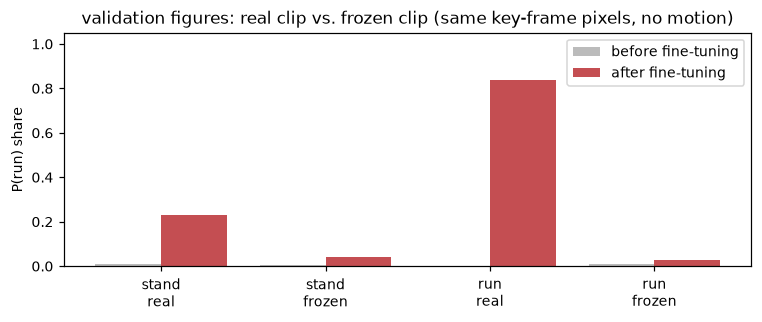

{'stand/real': 0.23, 'stand/frozen': 0.043, 'run/real': 0.838, 'run/frozen': 0.029}


In [27]:
after = motion_test(model_t, cfg_t)
labels_ = ["stand\nreal", "stand\nfrozen", "run\nreal", "run\nfrozen"]
keys_ = [("stand", "real"), ("stand", "frozen"), ("run", "real"), ("run", "frozen")]
fig, ax = plt.subplots(figsize=(7, 3)); xs = np.arange(4)
ax.bar(xs - 0.2, [before[k_] for k_ in keys_], 0.4, label="before fine-tuning", color="#BBBBBB")
ax.bar(xs + 0.2, [after[k_] for k_ in keys_], 0.4, label="after fine-tuning", color="#C44E52")
ax.set_xticks(xs, labels_); ax.set_ylabel("P(run) share"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("validation figures: real clip vs. frozen clip (same key-frame pixels, no motion)")
plt.tight_layout(); plt.show()
print({f"{c_}/{t_}": round(v, 3) for (c_, t_), v in after.items()})

(The grey "before" bars are ~0 or missing because the untrained AVA model doesn't even *detect* the grey
figures, so there's little or nothing to measure; see the mAP ≈ 0 at epoch 0.)

After fine-tuning, moving figures get a high $P(\text{run})$ **only when the clip contains motion**. Freeze the
very same pixels and the prediction flips to `stand`. The network is reading movement from the 32-frame input,
and that's the reason for a 3D backbone and a clip-based detector instead of an image detector.

Try it yourself: re-run with `HFLIP: False`, or with fewer epochs, or with `TEMP_LEN: 8` (a shorter temporal
window gives less evidence of motion).

## E4. The full inference tool

`infer_video.py` wraps everything above for long videos: it re-samples to 30 fps, keeps a sliding window of 32
frames, runs the model every 0.5 s, and writes an annotated MP4 and a CSV. Here it runs for 10 s on `vtest`
with the zero-shot AVA model:

wrote outputs\notebook_vtest.csv and outputs\notebook_vtest.mp4
138 CSV rows; first 5:
   {'time_sec': '0.00', 'person_id_in_frame': '0', 'person_score': '0.994', 'x1': '0.3325', 'y1': '0.3828', 'x2': '0.3667', 'y2': '0.5312', 'action': 'stand', 'score': '0.811'}
   {'time_sec': '0.00', 'person_id_in_frame': '1', 'person_score': '0.992', 'x1': '0.8312', 'y1': '0.4155', 'x2': '0.8719', 'y2': '0.5571', 'action': 'stand', 'score': '0.604'}
   {'time_sec': '0.00', 'person_id_in_frame': '1', 'person_score': '0.992', 'x1': '0.8312', 'y1': '0.4155', 'x2': '0.8719', 'y2': '0.5571', 'action': 'walk', 'score': '0.419'}
   {'time_sec': '0.00', 'person_id_in_frame': '2', 'person_score': '0.983', 'x1': '0.6570', 'y1': '0.2788', 'x2': '0.6868', 'y2': '0.4087', 'action': 'stand', 'score': '0.575'}
   {'time_sec': '0.00', 'person_id_in_frame': '2', 'person_score': '0.983', 'x1': '0.6570', 'y1': '0.2788', 'x2': '0.6868', 'y2': '0.4087', 'action': 'walk', 'score': '0.436'}


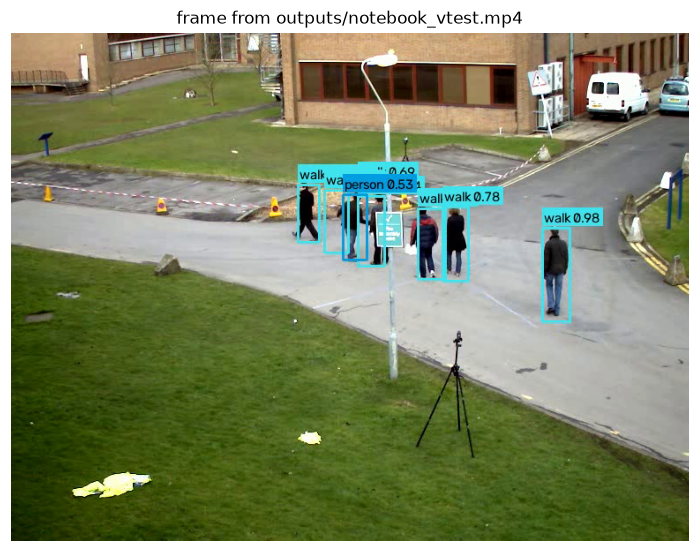

In [28]:
del model_t; torch.cuda.empty_cache()
r = subprocess.run([sys.executable, "infer_video.py", "--config", "configs/ava_zero_shot.yaml", "--checkpoint", "",
                    "--video", "data/samples/vtest.avi", "--out", "outputs/notebook_vtest", "--max-sec", "10"],
                   capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
import csv as _csv
rows = list(_csv.DictReader(open("outputs/notebook_vtest.csv")))
print(f"{len(rows)} CSV rows; first 5:")
for r_ in rows[:5]: print("  ", r_)
import cv2
cap = cv2.VideoCapture("outputs/notebook_vtest.mp4"); cap.set(cv2.CAP_PROP_POS_FRAMES, 200); ok, fr = cap.read()
plt.figure(figsize=(8, 6)); plt.imshow(fr[..., ::-1]); plt.axis("off"); plt.title("frame from outputs/notebook_vtest.mp4"); plt.show()

---
# Recap

| Concept | One-line intuition | Where in code |
|---|---|---|
| Clip + key frame | motion needs time: 32 frames ≈ 2 s around the moment you predict | `parktuber/dataset.py` |
| CSN backbone | 3D CNN made cheap by separating channel mixing from space-time filtering | `third_party/.../ir_CSN_152.py` |
| Temporal pooling (`decode`) | a learned query picks what matters along time; **must match the checkpoint** | `backbone_builder.py`, `parktuber/checkpoint.py` |
| Tubelet queries | 15 slots, each grabs one person; no anchors, no NMS | `query_embed`, `transformer.py` |
| Action switch | per-slot "is this a person?" | `class_embed_b` |
| Context-aware head | action classifier attends to the whole space-time scene, not just the box | `class_proj`, `cross_attn`, `class_fc` |
| Hungarian matching | one-to-one assignment of slots to people during training | `models/detr/matcher.py` |
| Losses | switch CE + multi-label BCE + L1 + GIoU, on all 6 decoder layers | `models/criterion.py` |
| frame-mAP@0.5 | per-class AP of key-frame detections at IoU 0.5 | `parktuber/engine.py` → upstream evaluator |
| Fine-tuning | map AVA classes to yours, freeze most of the backbone, bf16 + grad accumulation | `configs/`, `parktuber/model.py`, `engine.py` |

**Next:** annotate a pilot set of your park footage (`docs/03`), get the zero-shot baseline, then fine-tune
(`docs/04`). Re-run B4–B9 on *your* videos: the attention maps and query statistics say a lot about the domain gap.